In [1]:
import cv2 as cv
import matplotlib.pyplot as plt

from core.entities.constants import Paths as p

In [2]:
img_path = p.IMAGE_ASSETS / "lambo.jpg"
img = cv.imread(img_path)

In [3]:
scale_factor = 0.5

h, w, _ = img.shape
h_resized = int(h * scale_factor)
w_resized = int(w * scale_factor)

img = cv.resize(img, (w_resized, h_resized), interpolation=cv.INTER_LINEAR)

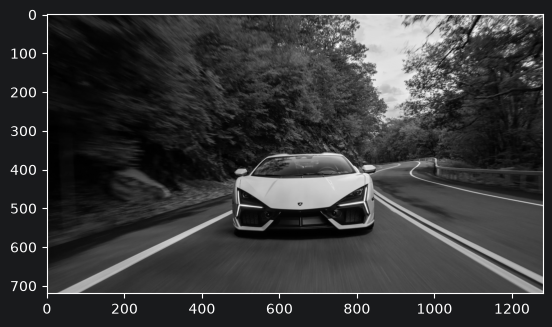

In [4]:
gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

plt.figure()
plt.imshow(gray, cmap='gray')

In [5]:

from dataclasses import dataclass

@dataclass(frozen=True)
class TrackbarConst:
    MIN_THRESHOLD: str = "min_t"
    MAX_THRESHOLD: str = "max_t"
    APERTURE_SIZE: str = "a_size" # sobel kernel
    L2_GRADIENT: str = "l2_gradient"

    MIN_T_VALUE: int = 0
    MAX_T_VALUE: int = 255
    MIN_APERTURE: int = 3
    MAX_APERTURE: int = 7
    L2_GRADIENT_MIN: int = 0
    L2_GRADIENT_MAX: int = 1

In [6]:
def canny_callback(value: int) -> None:
    pass

In [7]:
window_name = "canny edge detection"
cv.namedWindow(window_name)

cv.createTrackbar(TrackbarConst.MIN_THRESHOLD, window_name, TrackbarConst.MIN_T_VALUE, TrackbarConst.MAX_T_VALUE, canny_callback)
cv.createTrackbar(TrackbarConst.MAX_THRESHOLD, window_name, TrackbarConst.MIN_T_VALUE, TrackbarConst.MAX_T_VALUE, canny_callback)
cv.createTrackbar(TrackbarConst.APERTURE_SIZE, window_name, TrackbarConst.MIN_APERTURE, TrackbarConst.MAX_APERTURE, canny_callback)
cv.setTrackbarMin(TrackbarConst.APERTURE_SIZE, window_name, TrackbarConst.MIN_APERTURE)
cv.setTrackbarMax(TrackbarConst.APERTURE_SIZE, window_name, TrackbarConst.MAX_APERTURE)
cv.createTrackbar(TrackbarConst.L2_GRADIENT, window_name, TrackbarConst.L2_GRADIENT_MIN, TrackbarConst.L2_GRADIENT_MAX, canny_callback)
cv.setTrackbarPos(TrackbarConst.L2_GRADIENT, window_name, TrackbarConst.L2_GRADIENT_MAX)

while True:
    if cv.waitKey(1) == ord("q"):
        break

    min_threshold = cv.getTrackbarPos(TrackbarConst.MIN_THRESHOLD, window_name)
    max_threshold = cv.getTrackbarPos(TrackbarConst.MAX_THRESHOLD, window_name)
    a_size = cv.getTrackbarPos(TrackbarConst.APERTURE_SIZE, window_name)
    l2_gradient = bool(cv.getTrackbarPos(TrackbarConst.L2_GRADIENT, window_name))

    if a_size % 2 == 0:
        a_size += 1
        cv.setTrackbarPos(TrackbarConst.APERTURE_SIZE, window_name, a_size)

    canny_edges = cv.Canny(gray, min_threshold, max_threshold, apertureSize=a_size, L2gradient=l2_gradient)

    overlay = img.copy()
    overlay[canny_edges != 0] = [0, 0, 255]

    cv.imshow(window_name, canny_edges)
    cv.imshow("overlay", overlay)
cv.destroyAllWindows()